In [1]:
!pip install -q ultralytics roboflow onnx onnxslim onnxruntime-gpu

import os
import glob
import shutil
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from ultralytics import YOLO

# Set seed untuk reproduksibilitas (Matematika Inti: Peluang & Statistik)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [6]:
!pip install roboflow

from roboflow import Roboflow
import os
rf = Roboflow(api_key=os.getenv("ROBOFLOW_API_KEY", "REDACTED_FOR_SECURITY"))
project = rf.workspace("insurance-slszr").project("car-dents-0xzs9")
version = project.version(3)
dataset = version.download("yolov8")
# Tambahan wajib di baris paling bawah:
RAW_DATA_DIR = dataset.location
print(f"Dataset berhasil dikumpulkan di: {RAW_DATA_DIR}")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Car-Dents-3 in yolov8:: 100%|██████████| 14528/14528 [00:01<00:00, 7754.88it/s] 

Dataset berhasil dikumpulkan di: /content/Car-Dents-3


In [7]:
# Langkah 3 & 4 Olah Data: Pahami Data & Bersihkan Data
image_files = glob.glob(f"{RAW_DATA_DIR}/**/images/*.*", recursive=True)

records = []
corrupt_or_invalid = 0

for img_path in image_files:
    label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

    # 1. Cek apakah file gambar corrupt / rusak
    try:
        with Image.open(img_path) as img:
            width, height = img.size
    except Exception:
        corrupt_or_invalid += 1
        os.remove(img_path)
        continue

    # 2. Cek apakah file label tersedia
    if not os.path.exists(label_path):
        corrupt_or_invalid += 1
        continue

    with open(label_path, "r") as f:
        lines = [line.strip() for line in f.readlines() if line.strip()]

    # 3. Bersihkan baris label & konversi otomatis jika ada format poligon menjadi bounding box
    for line in lines:
        parts = line.split()
        if len(parts) >= 5:
            cls_id = int(float(parts[0]))
            coords = [float(x) for x in parts[1:]]

            # Jika format standar YOLO (x_center, y_center, width, height)
            if len(coords) == 4:
                xc, yc, bw, bh = coords
            # Jika format poligon (x1, y1, x2, y2, ...), konversi ke bounding box
            else:
                xs = coords[0::2]
                ys = coords[1::2]
                min_x, max_x = min(xs), max(xs)
                min_y, max_y = min(ys), max(ys)
                xc = (min_x + max_x) / 2.0
                yc = (min_y + max_y) / 2.0
                bw = max_x - min_x
                bh = max_y - min_y

            if all(0.0 <= c <= 1.0 for c in [xc, yc, bw, bh]) and bw > 0 and bh > 0:
                records.append({
                    "image_path": img_path,
                    "label_path": label_path,
                    "width": width,
                    "height": height,
                    "class_id": cls_id,
                    "x_center": xc,
                    "y_center": yc,
                    "box_width": bw,
                    "box_height": bh
                })
            else:
                corrupt_or_invalid += 1
        else:
            corrupt_or_invalid += 1

df_data = pd.DataFrame(records)

# Tampilkan informasi dataset (Pahami Data & Bersihkan Data)
print("=== INFORMASI DATASET (PAHAMI & BERSIHKAN DATA) ===")
print(f"Jumlah total anotasi objek (baris) : {len(df_data)}")
print(f"Jumlah gambar unik yang bersih     : {df_data['image_path'].nunique()}")
print(f"Data kosong/rusak yang dibersihkan : {corrupt_or_invalid}")
print("\nTipe Data Setiap Kolom:")
print(df_data.dtypes)

before_dedup = len(df_data)
df_data = df_data.drop_duplicates()
print(f"\nDuplikat dihapus: {before_dedup - len(df_data)} baris")
df_data.head()

=== INFORMASI DATASET (PAHAMI & BERSIHKAN DATA) ===
Jumlah total anotasi objek (baris) : 7777
Jumlah gambar unik yang bersih     : 7258
Data kosong/rusak yang dibersihkan : 0

Tipe Data Setiap Kolom:
image_path     object
label_path     object
width           int64
height          int64
class_id        int64
x_center      float64
y_center      float64
box_width     float64
box_height    float64
dtype: object

Duplikat dihapus: 0 baris


,image_path,label_path,width,height,class_id,x_center,y_center,box_width,box_height
0,/content/Car-Dents-3/train/images/car-has-dent...,/content/Car-Dents-3/train/labels/car-has-dent...,640,640,1,0.680046,0.616177,0.373797,0.227181
1,/content/Car-Dents-3/train/images/22_jpg.rf.db...,/content/Car-Dents-3/train/labels/22_jpg.rf.db...,640,640,0,0.511166,0.483189,0.246550,0.396350
2,/content/Car-Dents-3/train/images/Car-dents-da...,/content/Car-Dents-3/train/labels/Car-dents-da...,640,640,0,0.549988,0.402617,0.833439,0.729589
3,/content/Car-Dents-3/train/images/u34739473343...,/content/Car-Dents-3/train/labels/u34739473343...,640,640,0,0.751330,0.635057,0.497340,0.464251
4,/content/Car-Dents-3/train/images/data1055_jpg...,/content/Car-Dents-3/train/labels/data1055_jpg...,640,640,1,0.496891,0.463663,0.269891,0.277061


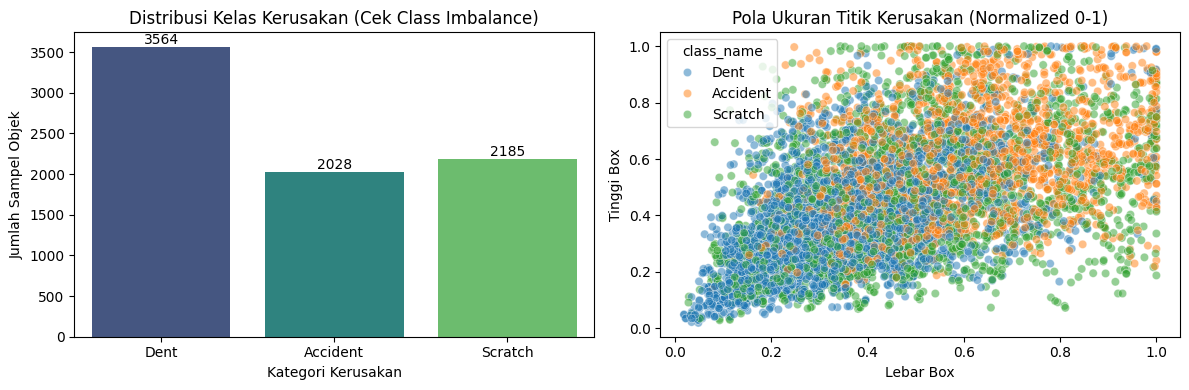


=== JUMLAH OBJEK PER KELAS ===
class_name
Dent        3564
Scratch     2185
Accident    2028
Name: count, dtype: int64

=== STATISTIK DESKRIPTIF UKURAN BOX ===
         box_width   box_height
count  7777.000000  7777.000000
mean      0.449381     0.448863
std       0.224898     0.217062
min       0.018750     0.019314
25%       0.271987     0.278528
50%       0.412500     0.419531
75%       0.596414     0.595313
max       1.000000     1.000000


In [8]:
import yaml

# Baca nama kelas dari data.yaml bawaan dataset
with open(f"{RAW_DATA_DIR}/data.yaml", "r") as f:
    raw_yaml = yaml.safe_load(f)

class_names = raw_yaml.get("names", ["Class 0", "Class 1", "Class 2"])
df_data["class_name"] = df_data["class_id"].apply(
    lambda i: class_names[i] if i < len(class_names) else f"Class {i}"
)

plt.figure(figsize=(12, 4))

# Grafik 1: Distribusi Kelas (Cek Class Imbalance)
plt.subplot(1, 2, 1)
ax = sns.countplot(data=df_data, x="class_name", hue="class_name", palette="viridis", legend=False)
plt.title("Distribusi Kelas Kerusakan (Cek Class Imbalance)")
plt.xlabel("Kategori Kerusakan")
plt.ylabel("Jumlah Sampel Objek")
for container in ax.containers:
    ax.bar_label(container)

# Grafik 2: Pola Ukuran Bounding Box (Lebar vs Tinggi Kerusakan)
plt.subplot(1, 2, 2)
sns.scatterplot(data=df_data, x="box_width", y="box_height", hue="class_name", alpha=0.5)
plt.title("Pola Ukuran Titik Kerusakan (Normalized 0-1)")
plt.xlabel("Lebar Box")
plt.ylabel("Tinggi Box")

plt.tight_layout()
plt.show()

print("\n=== JUMLAH OBJEK PER KELAS ===")
print(df_data["class_name"].value_counts())
print("\n=== STATISTIK DESKRIPTIF UKURAN BOX ===")
print(df_data[["box_width", "box_height"]].describe())

In [9]:
# Ambil daftar gambar unik agar 1 gambar tidak bocor ke train sekaligus test
unique_images = df_data["image_path"].unique().tolist()
random.seed(SEED)
random.shuffle(unique_images)

n_total = len(unique_images)
n_train = int(0.70 * n_total)
n_val   = int(0.15 * n_total)

train_imgs = unique_images[:n_train]
val_imgs   = unique_images[n_train:n_train + n_val]
test_imgs  = unique_images[n_train + n_val:]

print("=== PEMBAGIAN DATA (70% / 15% / 15%) ===")
print(f"Total Gambar Unik : {n_total} gambar")
print(f"70% Training      : {len(train_imgs)} gambar (Model Belajar)")
print(f"15% Validation    : {len(val_imgs)} gambar (Memilih Model & Pengaturan)")
print(f"15% Test          : {len(test_imgs)} gambar (Ujian Akhir Satu Kali - Bebas Data Leakage)")

# Buat struktur folder bersih 70/15/15
CLEAN_DIR = "/content/motolens_clean_70_15_15"
if os.path.exists(CLEAN_DIR):
    shutil.rmtree(CLEAN_DIR)

for split in ["train", "val", "test"]:
    os.makedirs(f"{CLEAN_DIR}/{split}/images", exist_ok=True)
    os.makedirs(f"{CLEAN_DIR}/{split}/labels", exist_ok=True)

# Kelompokkan bounding box bersih per gambar dari df_data
grouped_boxes = df_data.groupby("image_path")

def export_clean_split(img_list, split_name):
    for img_path in img_list:
        filename = os.path.basename(img_path)
        base_name = os.path.splitext(filename)[0]

        # Salin file gambar
        dst_img = f"{CLEAN_DIR}/{split_name}/images/{filename}"
        shutil.copy(img_path, dst_img)

        # Tulis file label (.txt) dari data yang sudah dibersihkan
        dst_lbl = f"{CLEAN_DIR}/{split_name}/labels/{base_name}.txt"
        boxes = grouped_boxes.get_group(img_path)
        with open(dst_lbl, "w") as f:
            for _, row in boxes.iterrows():
                f.write(f"{int(row['class_id'])} {row['x_center']:.6f} {row['y_center']:.6f} {row['box_width']:.6f} {row['box_height']:.6f}\n")

export_clean_split(train_imgs, "train")
export_clean_split(val_imgs, "val")
export_clean_split(test_imgs, "test")

# Simpan file konfigurasi data.yaml baru
clean_yaml = {
    "path": CLEAN_DIR,
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": len(class_names),
    "names": class_names
}

with open(f"{CLEAN_DIR}/data.yaml", "w") as f:
    yaml.dump(clean_yaml, f)

print(f"\nDataset bersih berhasil disiapkan di: {CLEAN_DIR}/data.yaml")
print(f"Kelas terdeteksi: {class_names}")

=== PEMBAGIAN DATA (70% / 15% / 15%) ===
Total Gambar Unik : 7258 gambar
70% Training      : 5080 gambar (Model Belajar)
15% Validation    : 1088 gambar (Memilih Model & Pengaturan)
15% Test          : 1090 gambar (Ujian Akhir Satu Kali - Bebas Data Leakage)

Dataset bersih berhasil disiapkan di: /content/motolens_clean_70_15_15/data.yaml
Kelas terdeteksi: ['Accident', 'Dent', 'Scratch']


In [10]:
# Tahap 4 Roadmap: Machine Learning / Deep Learning untuk Data Gambar
# Membandingkan Model Baseline vs Model Tuned (Sesuai Langkah 4 Evaluasi Model)

# 1. LATIH MODEL BASELINE (3 Epochs, Tanpa Augmentasi Kompleks)
print("=== MULAI TRAINING MODEL BASELINE ===")
baseline_model = YOLO("yolov8n.pt")
baseline_model.train(
    data=f"{CLEAN_DIR}/data.yaml",
    epochs=3,
    imgsz=640,
    batch=32,
    workers=2,
    augment=False,
    amp=True,
    name="motolens_baseline",
    seed=SEED
)

# 2. LATIH MODEL UTAMA / TUNED (20 Epochs, AdamW Optimizer + Augmentasi)
print("\n=== MULAI TRAINING MODEL UTAMA (TUNED) ===")
tuned_model = YOLO("yolov8n.pt")
tuned_model.train(
    data=f"{CLEAN_DIR}/data.yaml",
    epochs=20,
    imgsz=640,
    batch=32,
    workers=2,
    patience=7,
    optimizer="AdamW",
    lr0=0.001,
    amp=True,
    name="motolens_tuned",
    seed=SEED
)

=== MULAI TRAINING MODEL BASELINE ===
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/motolens_clean_70_15_15/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=motolens_

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78f9b3874980>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 906.7±310.2 MB/s, size: 47.6 KB)
val: Scanning /content/motolens_clean_70_15_15/test/labels... 1090 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1090/1090 1.3Kit/s 0.9s
val: New cache created: /content/motolens_clean_70_15_15/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 69/69 5.4it/s 12.7s
                   all       1090       1187      0.633      0.542      0.595      0.402
              Accident        310        313      0.538      0.489      0.514      0.314
                  Dent        509        540      0.678      0.642      0.695      0.477
               Scratch        306        334      0.685      0.494      0.575      0.415
Speed: 1.2ms preprocess, 4.4ms inference, 0.0ms los

,Model,Precision,Recall,F1-Score,mAP@50 (Accuracy Deteksi),mAP@50-95
0,"Baseline (3 Epochs, Tanpa Augmentasi)",0.6335,0.5417,0.5840,0.5947,0.4019
1,"MotoLens Tuned (20 Epochs, AdamW)",0.8404,0.7414,0.7878,0.8367,0.6558


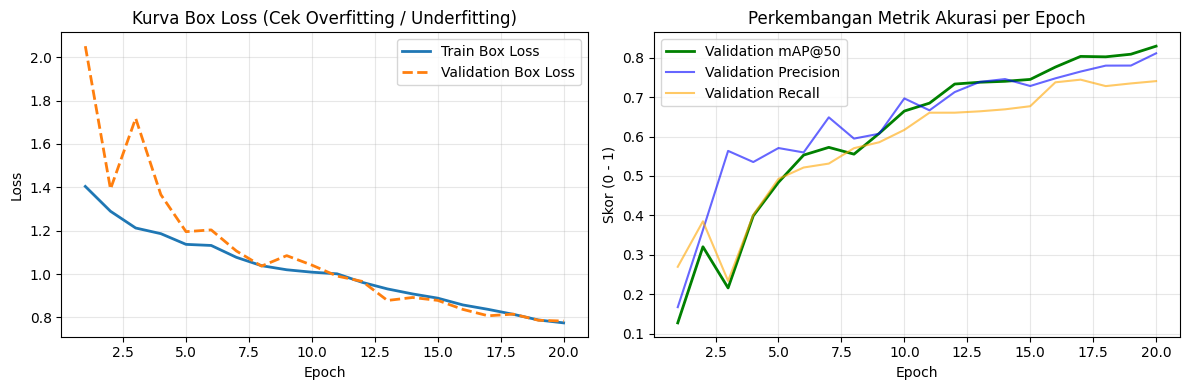

In [11]:
# Tahap 5 Roadmap: Evaluasi Model (Langkah 2, 3, dan 4)
best_baseline = YOLO("runs/detect/motolens_baseline/weights/best.pt")
best_tuned    = YOLO("runs/detect/motolens_tuned/weights/best.pt")

# Ujian akhir satu kali pada Test Set (15% = 1090 gambar)
metrics_base  = best_baseline.val(data=f"{CLEAN_DIR}/data.yaml", split="test")
metrics_tuned = best_tuned.val(data=f"{CLEAN_DIR}/data.yaml", split="test")

def calc_f1(p, r):
    return 2 * (p * r) / (p + r + 1e-8)

# Tabel Perbandingan Baseline vs Model Tuned
df_eval = pd.DataFrame([
    {
        "Model": "Baseline (3 Epochs, Tanpa Augmentasi)",
        "Precision": round(float(metrics_base.box.mp), 4),
        "Recall": round(float(metrics_base.box.mr), 4),
        "F1-Score": round(calc_f1(float(metrics_base.box.mp), float(metrics_base.box.mr)), 4),
        "mAP@50 (Accuracy Deteksi)": round(float(metrics_base.box.map50), 4),
        "mAP@50-95": round(float(metrics_base.box.map), 4)
    },
    {
        "Model": "MotoLens Tuned (20 Epochs, AdamW)",
        "Precision": round(float(metrics_tuned.box.mp), 4),
        "Recall": round(float(metrics_tuned.box.mr), 4),
        "F1-Score": round(calc_f1(float(metrics_tuned.box.mp), float(metrics_tuned.box.mr)), 4),
        "mAP@50 (Accuracy Deteksi)": round(float(metrics_tuned.box.map50), 4),
        "mAP@50-95": round(float(metrics_tuned.box.map), 4)
    }
])

print("\n=== TABEL PERBANDINGAN METRIK PADA TEST SET (15%) ===")
display(df_eval)

# Cek Masalah Overfitting vs Underfitting dari Grafik Loss
results_csv = "runs/detect/motolens_tuned/results.csv"
df_log = pd.read_csv(results_csv)
df_log.columns = [c.strip() for c in df_log.columns]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(df_log["epoch"], df_log["train/box_loss"], label="Train Box Loss", linewidth=2)
plt.plot(df_log["epoch"], df_log["val/box_loss"], label="Validation Box Loss", linewidth=2, linestyle="--")
plt.title("Kurva Box Loss (Cek Overfitting / Underfitting)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(df_log["epoch"], df_log["metrics/mAP50(B)"], label="Validation mAP@50", color="green", linewidth=2)
plt.plot(df_log["epoch"], df_log["metrics/precision(B)"], label="Validation Precision", color="blue", alpha=0.6)
plt.plot(df_log["epoch"], df_log["metrics/recall(B)"], label="Validation Recall", color="orange", alpha=0.6)
plt.title("Perkembangan Metrik Akurasi per Epoch")
plt.xlabel("Epoch")
plt.ylabel("Skor (0 - 1)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [12]:
from google.colab import files

# 1. AMANKAN DULU MODEL YANG SEKARANG SEBAGAI CADANGAN
best_tuned_v1 = YOLO("runs/detect/motolens_tuned/weights/best.pt")
onnx_v1 = best_tuned_v1.export(format="onnx", imgsz=640, simplify=True)
shutil.copy(onnx_v1, "model_damage_v1_83pct.onnx")
files.download("model_damage_v1_83pct.onnx")
print("Cadangan model v1 (mAP 83.67%) berhasil diamankan!\n")

# 2. FINE-TUNING LANJUTAN (+20 EPOCHS DENGAN COSINE LR & PENAJAMAN)
print("=== MULAI FINE-TUNING TAHAP 2 (OPTIMIZED MODEL) ===")
optimized_model = YOLO("runs/detect/motolens_tuned/weights/best.pt")
optimized_model.train(
    data=f"{CLEAN_DIR}/data.yaml",
    epochs=20,
    imgsz=640,
    batch=32,
    workers=2,
    optimizer="AdamW",
    lr0=0.0005,        # Learning rate lebih halus untuk penajaman koordinat box
    lrf=0.01,
    cos_lr=True,       # Cosine learning rate scheduler agar konvergensi maksimal
    close_mosaic=10,   # Matikan mosaic di 10 epoch terakhir agar fokus pada gambar utuh
    amp=True,
    name="motolens_optimized_v2",
    seed=SEED
)

# 3. BANDINGKAN 3 TAHAP MODEL PADA TEST SET (15%)
best_opt_v2 = YOLO("runs/detect/motolens_optimized_v2/weights/best.pt")
metrics_opt_v2 = best_opt_v2.val(data=f"{CLEAN_DIR}/data.yaml", split="test")

df_eval_3 = pd.DataFrame([
    {
        "Model": "1. Baseline (3 Epochs)",
        "Precision": round(float(metrics_base.box.mp), 4),
        "Recall": round(float(metrics_base.box.mr), 4),
        "F1-Score": round(calc_f1(float(metrics_base.box.mp), float(metrics_base.box.mr)), 4),
        "mAP@50": round(float(metrics_base.box.map50), 4),
        "mAP@50-95": round(float(metrics_base.box.map), 4)
    },
    {
        "Model": "2. Tuned v1 (20 Epochs, AdamW)",
        "Precision": round(float(metrics_tuned.box.mp), 4),
        "Recall": round(float(metrics_tuned.box.mr), 4),
        "F1-Score": round(calc_f1(float(metrics_tuned.box.mp), float(metrics_tuned.box.mr)), 4),
        "mAP@50": round(float(metrics_tuned.box.map50), 4),
        "mAP@50-95": round(float(metrics_tuned.box.map), 4)
    },
    {
        "Model": "3. Optimized v2 (+20 Epochs, Cosine LR)",
        "Precision": round(float(metrics_opt_v2.box.mp), 4),
        "Recall": round(float(metrics_opt_v2.box.mr), 4),
        "F1-Score": round(calc_f1(float(metrics_opt_v2.box.mp), float(metrics_opt_v2.box.mr)), 4),
        "mAP@50": round(float(metrics_opt_v2.box.map50), 4),
        "mAP@50-95": round(float(metrics_opt_v2.box.map), 4)
    }
])

print("\n=== TABEL PERBANDINGAN 3 EKSPERIMEN MODEL PADA TEST SET (15%) ===")
display(df_eval_3)

# 4. EKSPOR & UNDUH MODEL FINAL TERBAIK KE model_damage.onnx
onnx_final = best_opt_v2.export(format="onnx", imgsz=640, simplify=True)
shutil.copy(onnx_final, "model_damage.onnx")
files.download("model_damage.onnx")

Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from 'runs/detect/motolens_tuned/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 3.6s, saved as 'runs/detect/motolens_tuned/weights/best.onnx' (12.2 MB)

Export complete (3.8s)
Results saved to /content/runs/detect/motolens_tuned/weights/best.onnx
Predict:         yolo predict task=detect model=runs/detect/motolens_tuned/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=runs/detect/motolens_tuned/weights/best.onnx imgsz=640 data=/content/motolens_clean_70_15_15/data.yaml 
Visualize

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Cadangan model v1 (mAP 83.67%) berhasil diamankan!

=== MULAI FINE-TUNING TAHAP 2 (OPTIMIZED MODEL) ===
Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/motolens_clean_70_15_15/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.0005, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=run

,Model,Precision,Recall,F1-Score,mAP@50,mAP@50-95
0,1. Baseline (3 Epochs),0.6335,0.5417,0.5840,0.5947,0.4019
1,"2. Tuned v1 (20 Epochs, AdamW)",0.8404,0.7414,0.7878,0.8367,0.6558
2,"3. Optimized v2 (+20 Epochs, Cosine LR)",0.8252,0.7592,0.7908,0.8434,0.6754


Ultralytics 8.4.211 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
Model summary (fused): 73 layers, 3,133,193 parameters, 0 gradients, 8.6 GFLOPs

PyTorch: starting from 'runs/detect/motolens_optimized_v2/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 7, 8400) (6.2 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 1.1s, saved as 'runs/detect/motolens_optimized_v2/weights/best.onnx' (12.2 MB)

Export complete (1.4s)
Results saved to /content/runs/detect/motolens_optimized_v2/weights/best.onnx
Predict:         yolo predict task=detect model=runs/detect/motolens_optimized_v2/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=runs/detect/motolens_optimized_v2/weights/best.onnx imgsz=640 data=/content/motolens_clean_70_15_15/data.yaml 
Visualize:       https://netron.app


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Loading model_damage.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.31.1 with CUDAExecutionProvider
=== SIMULASI PROYEK NYATA MOTOLENS (DATA -> MODEL -> PREDIKSI) ===
File Gambar Uji       : u34739473343570624308fm253fmtautoapp138fJPEG_jpg.rf.c0ffa6eaba1522bd0e4194bf8cd15c52.jpg
Deteksi Kerusakan AI  : Baret (Scratch)=0, Penyok (Dent)=1, Rusak Berat/Retak (Accident)=0
Total Depresiasi Fisik: -5.0%
Harga Pasar Normal    : Rp 18,500,000
Taksiran Harga AI     : Rp 17,575,000


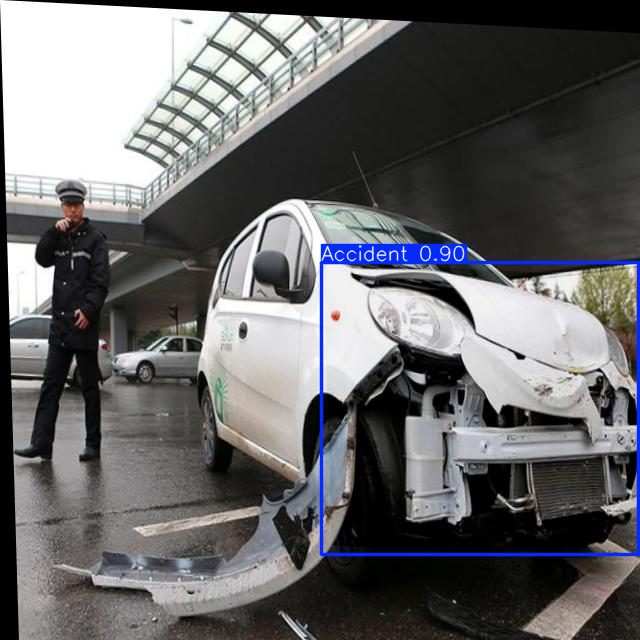

In [13]:
from google.colab.patches import cv2_imshow

# Uji model_damage.onnx versi final (Optimized v2) pada data Test
onnx_detector = YOLO("model_damage.onnx", task="detect")
sample_test_images = glob.glob(f"{CLEAN_DIR}/test/images/*.*")

for img_candidate in sample_test_images[:30]:
    pred = onnx_detector.predict(source=img_candidate, conf=0.35, verbose=False)
    if len(pred[0].boxes) > 0:
        sample_img = img_candidate
        break

counts = {"scratch": 0, "dent": 0, "crack": 0}
for box in pred[0].boxes:
    cls_name = pred[0].names[int(box.cls[0])].lower()
    if "scratch" in cls_name:
        counts["scratch"] += 1
    elif "dent" in cls_name:
        counts["dent"] += 1
    else:
        counts["crack"] += 1

harga_dasar_pasar = 18500000
potongan_fisik = min(counts["scratch"] * 0.025, 0.10) + \
                 min(counts["dent"] * 0.05, 0.15) + \
                 min(counts["crack"] * 0.075, 0.20)
harga_rekomendasi_ai = int(harga_dasar_pasar * (1 - potongan_fisik))

print("=== SIMULASI PROYEK NYATA MOTOLENS (DATA -> MODEL -> PREDIKSI) ===")
print(f"File Gambar Uji       : {os.path.basename(sample_img)}")
print(f"Deteksi Kerusakan AI  : Baret (Scratch)={counts['scratch']}, Penyok (Dent)={counts['dent']}, Rusak Berat/Retak (Accident)={counts['crack']}")
print(f"Total Depresiasi Fisik: -{potongan_fisik * 100:.1f}%")
print(f"Harga Pasar Normal    : Rp {harga_dasar_pasar:,}")
print(f"Taksiran Harga AI     : Rp {harga_rekomendasi_ai:,}")

cv2_imshow(pred[0].plot())